# CFSPOPCON, starting from the beginning

This notebook assumes you have not used CFSPOPCON, xarray, Pint, or these
input files before. Use **Python (ZClass)** and run cells in order. A cell
can use a variable created in an earlier cell; start with **Restart Kernel
and Run All Cells** if you lose track of the notebook's state.

We will learn one calculation first, then run the supplied SPARC example,
then adapt it to FIRE H-mode. The confinement scan and operating-limit
exercise come after the basic workflow. You can stop at the first POPCON
and return to those exercises later.

### What calculation are we asking the computer to do?

Pick a tokamak's size, field, current, fuel, and model assumptions. Choose
an average electron density and temperature. The program estimates the
stored plasma energy, fusion heating, radiation, and energy loss. It then
finds how much **auxiliary heating** is required to maintain that state.
Repeat at many density/temperature pairs and draw contours of the results.
This is a steady-state scoping model. It does not simulate a discharge
evolving in time or solve a full plasma transport problem.

At a steady point the accounting is

$$P_{aux,absorbed}+P_{ohmic}+P_\alpha=P_{SOL}+P_{radiation}.$$

| Term | Meaning |
|---|---|
| Auxiliary heating | External heating, for example radio-frequency heating or neutral beams. |
| Ohmic heating | Heating associated with driving current through a resistive plasma. |
| Alpha heating | Energy deposited by charged fusion products. Most D-T fusion energy leaves in neutrons instead. |
| Radiation | Energy leaving the confined plasma as electromagnetic radiation. Impurity species affect this loss. |
| SOL power | Power crossing the boundary of the confined plasma into the scrape-off layer (SOL). |

CFSPOPCON calls the total required heating/loss power `P_in`. Its confinement
model sets `P_in = W / tau_E`, where W is stored thermal energy and tau_E is
the energy confinement time. This lets it calculate the signed requirement
`P_in - P_alpha - P_ohmic`. `P_fusion` includes all fusion power; it must not
be substituted for `P_alpha` in this balance.

### How the files and code fit together

```text
input.yaml: machine values + grid + ordered calculation names
    -> read_case(): prepare inputs and the calculation recipe
    -> xr.Dataset(...): put named inputs in one container
    -> algorithm.update_dataset(...): calculate new named quantities
    -> results + plot settings -> make_plot(): draw the POPCON
```

This order follows the official [Creating your first POPCON](https://cfspopcon.readthedocs.io/en/latest/doc_sources/getting_started.html)
and [Understanding algorithms](https://cfspopcon.readthedocs.io/en/latest/doc_sources/understanding_algorithms.html)
tutorials. Function details below were also checked against the installed
version 9.0.0. The [Getting Started page](https://cfspopcon.readthedocs.io/en/latest/doc_sources/Usage.html)
covers installation. These are software instructions; the assignment's
written analysis remains your work.

## 1. Import the tools used in this notebook

`import cfspopcon as cfs` gives the installed package the short name `cfs`.
Calls beginning `cfs.` below belong to that package. `from ... import ...`
brings one particular function into this notebook so we can call it by name.

| Import | What we use it for |
|---|---|
| `cfspopcon`, `calc_greenwald_density_limit` | The plasma calculations. The latter is one individual formula from the package. |
| `ureg` | Pint's unit registry: `ureg.MA` means megaampere and `ureg.keV` means kiloelectronvolt. |
| `xarray as xr` | Containers for quantities labelled by density, temperature, radial position, and species. |
| `make_plot`, `matplotlib.pyplot as plt` | Draw a POPCON using a plot-settings file; display and save figures. |
| `numpy as np`, `pandas as pd` | Array operations and small readable tables/CSV files. |
| `Path`, `yaml` | Locate files and read YAML text into Python dictionaries. |
| `datetime`, `version`, `json`, `os`, `shutil` | Name output folders, record versions/settings, and copy input files. These handle files, not plasma physics. |

You do not need to write a class. CFSPOPCON supplies its own calculation
objects; we will learn what they contain and which methods to call.

In [1]:
from datetime import datetime
from importlib.metadata import version
from pathlib import Path
import json
import os
import shutil

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import yaml
import cfspopcon as cfs
from cfspopcon.plotting.plots import make_plot
from cfspopcon.unit_handling import ureg
from cfspopcon.formulas.metrics.greenwald_density import calc_greenwald_density_limit

## 2. Locate the files and choose the exercise parameters

A `Path` is a file or folder location. Joining a folder and a filename with
`/` builds a longer path. The code below finds this tutorial's folder when
running either the Python file or its notebook, including from ZachClass.
It prints the location so that file errors can be checked directly.

| File or folder, relative to this notebook | What it contains and who reads it |
|---|---|
| `tutorial.py` / `tutorial.ipynb` | This lesson, as Python source / notebook. Edit the Python source first. |
| `inputs/upstream_SPARC_PRD/input.yaml` | The original SPARC machine settings, grid, and calculation recipe; read by `cfs.read_case`. |
| `inputs/upstream_SPARC_PRD/plot_popcon.yaml` | Original temperature-versus-density figure instructions; read by `cfs.read_plot_style`. |
| `inputs/upstream_SPARC_PRD/plot_remapped.yaml` | An alternative original plot using different coordinates; kept as a reference, not used below. |
| `inputs/fire_h_mode.yaml` | Our FIRE teaching case, read by `cfs.read_case`. |
| `inputs/plot_fire.yaml` | Contour levels, colours, units, and labels for FIRE. |
| `inputs/radas_tutorial.yaml` | Settings used once to generate atomic tables. The POPCON calculation does not execute this file. |
| `inputs/radas_upstream.yaml` | Original, finer atomic-table settings for a later resolution check. |
| `radas_dir/output/*.nc` | Previously generated atomic tables, opened by the recipe's `read_atomic_data` calculation. |
| `outputs/<run>/` | New figures and tables from this execution. Each run has its own folder. |
| `SETUP.md`, `SOURCES.md`, `sources.json` | Setup commands, provenance, and copied-input checksums. |

A `.yaml` file is readable text containing names and values; `.nc` means
NetCDF, a binary scientific-data format. The installed package code is in
the Conda environment, not inside `inputs/`. The `cfs.__file__` printout
below shows where Python imported it from.

The parameters below control later exercises. The actual FIRE machine
settings will be read from YAML. The heating cap and beta limit are
illustrative choices, not published FIRE equipment limits. The inspection
point is also a chosen example, not a published operating temperature.

In [2]:
if "__file__" in globals():
    tutorial_dir = Path(__file__).resolve().parent
else:
    tutorial_dir = Path.cwd()
    if not (tutorial_dir / "inputs/fire_h_mode.yaml").exists():
        tutorial_dir = tutorial_dir / "POPCON/CFSPOPCON"

confinement_factors = [0.9, 1.03, 1.15]
auxiliary_power_limit_MW = 30.0  # illustrative, not a FIRE specification
normalized_beta_limit = 3.0     # conventional numerical beta_N, beta in percent
greenwald_fraction_limit = 1.0
minimum_P_SOL_over_P_LH = 1.0
sample_density_1e19_m3 = 45.0
sample_average_Te_keV = 8.0     # chosen for inspection, not a published FIRE temperature


print("Tutorial folder:", tutorial_dir)
print("Installed package:", cfs.__file__)

Tutorial folder: /home/youeric/openmc-projects/ZachClass/POPCON/CFSPOPCON
Installed package: /home/youeric/miniforge3/envs/ZClass/lib/python3.12/site-packages/cfspopcon/__init__.py


### The atomic tables and output folder

An impurity ion's average charge and radiation depend on density and
temperature. RADAS prepares lookup tables for those quantities from
OpenADAS atomic rates. CFSPOPCON interpolates these tables during a run;
a table is not a POPCON result and does not specify the tokamak geometry.

These tables already exist on this computer. On a fresh checkout, activate
`ZClass`, open a terminal in this folder, and run:

```bash
radas --config inputs/radas_tutorial.yaml --directory radas_dir
```

This is a one-time preparation step that downloads atomic rates and can
take several minutes. It is not a command to run on each notebook execution.
The first run of this notebook checks for the five species needed by the
upstream example. FIRE uses helium and argon; the other tables are needed
for SPARC. No OpenMC nuclear data is involved.

Our tutorial tables use 12 density by 40 temperature samples; the original
RADAS configuration uses 50 by 100. That **atomic interpolation grid** is
separate from the density/temperature grid of the POPCON. This coarse setup
demonstrates the workflow; it is not an exact reproduction of upstream's
numerical regression result. `SETUP.md` explains a finer-table check.

`mkdir(parents=True)` creates the output folder and its parents. The
timestamp distinguishes executions. Saving files does not change the model.

In [3]:
data_dir = tutorial_dir / "radas_dir"
atomic_config_file = tutorial_dir / "inputs/radas_tutorial.yaml"
for species in ["helium", "oxygen", "tungsten", "xenon", "argon"]:
    if not (data_dir / "output" / f"{species}.nc").exists():
        raise FileNotFoundError(f"Missing RADAS table for {species}. Follow SETUP.md first.")

run_dir = tutorial_dir / "outputs" / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
cases_dir = run_dir / "cases"
cases_dir.mkdir(parents=True)
print("CFSPOPCON version:", version("cfspopcon"))
print("Outputs:", run_dir)

CFSPOPCON version: 9.0.0
Outputs: /home/youeric/openmc-projects/ZachClass/POPCON/CFSPOPCON/outputs/20261015_192828_917990


## 3. Learn a single calculation and its units

The Greenwald density is a useful small example. The package evaluates

$$n_G[10^{20}\,m^{-3}]=\frac{I_p[MA]}{\pi a^2[m^2]}.$$

`calc_greenwald_density_limit(plasma_current, minor_radius)` takes a current
and a radius and returns a **quantity with units**. Multiplying a number by
`ureg.MA` attaches units; it is not just a label in a comment. A keV is an
energy unit used to express plasma temperature. `n20` is the package's unit
for a density measured in multiples of 10^20 particles per cubic metre.

For example, `7.7 * ureg.MA` and `7.7e6 * ureg.A` express the same current.
`.to(...)` converts a quantity to another unit. `.magnitude` then extracts
its numerical value. Keep units attached during physics calculations.

In [4]:
plasma_current = 7.7 * ureg.MA
minor_radius = 0.595 * ureg.m
greenwald_density = calc_greenwald_density_limit(plasma_current, minor_radius)
print("Current in amperes:", plasma_current.to(ureg.A))
print("Greenwald density:", greenwald_density.to(ureg.n20))
print("Same density in particles/m^3:", greenwald_density.to(ureg.m**-3))
print("Number in n20 units:", greenwald_density.to(ureg.n20).magnitude)

Current in amperes: 7700000.0 ampere
Greenwald density: 6.923200688129901 _1e20_per_cubic_metre
Same density in particles/m^3: 6.9232006881299e+20 / meter ** 3
Number in n20 units: 6.923200688129901


### What is an Algorithm? What is a Dataset?

A plain function receives arguments explicitly, as above. A CFSPOPCON
**Algorithm** is a package object that knows the names of the inputs a
function needs and the names of the outputs it produces. The **registry**
is the package's lookup of algorithm names to those objects.
`discover_builtin_algorithms()` fills that lookup with the installed
calculations; it does not run a POPCON or download data.

An xarray **Dataset** is a container accessed by quantity name, similar to
a Python dictionary. A **DataArray** is one quantity inside it: numbers
together with dimension labels and, here, physical units. A Dataset can
contain a single current, a list of temperatures, and a two-dimensional
fusion-power array together. A scalar has no scan dimensions, shown as `()`.

In the next cell, `update_dataset` looks up `plasma_current` and
`minor_radius` by name, calculates `greenwald_density_limit`, and returns a
new Dataset containing both inputs and output. Keep the returned object:
merely calling the method without assigning its result would lose that result.

In [5]:
cfs.discover_builtin_algorithms()
density_limit_algorithm = cfs.registry["calc_greenwald_density_limit"]
print("Required inputs:", density_limit_algorithm.required_input_keys)
print("Outputs:", density_limit_algorithm.return_keys)

example_inputs = xr.Dataset({"plasma_current": plasma_current, "minor_radius": minor_radius})
example_result = density_limit_algorithm.update_dataset(example_inputs)
print(example_result)
print("Access one named result:", example_result["greenwald_density_limit"])

Required inputs: ['plasma_current', 'minor_radius']
Outputs: ['greenwald_density_limit']
<xarray.Dataset> Size: 24B
Dimensions:                  ()
Data variables:
    greenwald_density_limit  float64 8B [1e19 m^-3] 69.23
    plasma_current           float64 8B [MA] 7.7
    minor_radius             float64 8B [m] 0.595
Access one named result: <xarray.DataArray 'greenwald_density_limit' ()> Size: 8B
<Quantity(69.23200688129901, '_1e19_per_cubic_metre')>


## 4. Open the upstream input before running it

**SPARC_PRD** means SPARC primary reference discharge. We start with the
supplied example to learn the software before changing the machine.
`yaml.safe_load` turns YAML text into an ordinary Python dictionary, without
running any plasma calculations. We use it here to inspect the file.

The file has four special sections plus ordinary named inputs:

| Section | Purpose |
|---|---|
| `algorithms` | Ordered names of calculations to run. A later calculation can use an earlier output. |
| `grid` | Which input values vary: `min`, `max`, and `num` define samples along each axis. The actual key in our installed version is singular `grid`. |
| `points` | Rules for finding an example operating point, such as maximum Q subject to listed constraints. This does not change the power-balance calculation. |
| `plots` | Figure titles mapped to plot-settings files. These settings do not change the plasma calculation either. |
| Ordinary entries, e.g. `major_radius` | Fixed values or model choices used throughout that case. |

The printed grid below gives 40 densities and 30 temperatures, hence
1,200 combinations. It does **not** mean 40 independent tokamaks.
Densities in this YAML are in 10^19 m^-3, temperatures in keV, current in A,
lengths in m, field in T, and powers in MW. A value of 45 in the density
convention would mean 4.5e20 m^-3. Mean density/temperature here are volume
averages, not the hotter/denser values at the magnetic axis.

In [6]:
upstream_file = tutorial_dir / "inputs/upstream_SPARC_PRD/input.yaml"
with open(upstream_file) as file:
    upstream_raw = yaml.safe_load(file)
print("File being read:", upstream_file)
print("Grid definition:\n", yaml.safe_dump(upstream_raw["grid"], sort_keys=False))
print("First eight calculation names:", upstream_raw["algorithms"][:8])
print("Point-selection rules:\n", yaml.safe_dump(upstream_raw["points"], sort_keys=False))
print("Plot file references:", upstream_raw["plots"])

File being read: /home/youeric/openmc-projects/ZachClass/POPCON/CFSPOPCON/inputs/upstream_SPARC_PRD/input.yaml
Grid definition:
 average_electron_density:
  min: 1.0
  max: 40.0
  num: 40
  spacing: linear
average_electron_temp:
  min: 5.0
  max: 20.0
  num: 30
  spacing: linear

First eight calculation names: ['read_atomic_data', 'set_up_impurity_concentration_array', 'calc_separatrix_elongation_from_areal_elongation', 'calc_separatrix_triangularity_from_triangularity95', 'calc_minor_radius_from_inverse_aspect_ratio', 'calc_vertical_minor_radius_from_elongation_and_minor_radius', 'calc_plasma_volume', 'calc_plasma_surface_area']
Point-selection rules:
 PRD:
  maximize: Q
  where:
    P_auxiliary_launched:
      min: 0.0
      max: 25.0
      units: MW
    greenwald_fraction:
      max: 0.9
    ratio_of_P_SOL_to_P_LH:
      min: 1.0
    P_fusion:
      max: 140.0
      units: MW

Plot file references: {'POPCON for SPARC PRD': 'CASE_DIR/plot_popcon.yaml', 'SPARC PRD $(n_e, P_{aux})$': '

### Read the case: one call, four returned objects

`cfs.read_case(upstream_file)` prepares the file for calculation. It accepts
a YAML filename, or a folder containing a file named `input.yaml`.
It turns the grid specifications into labelled arrays, attaches the package's
default units, resolves special option names, and assembles the ordered
calculations into a **CompositeAlgorithm** (a sequence of Algorithms).
It does not yet calculate the POPCON.

| Variable receiving a return value | What it is | How we use it |
|---|---|---|
| `upstream_inputs` | Dictionary of prepared physical inputs | Put it in `xr.Dataset`. |
| `upstream_algorithm` | The ordered calculation recipe | Validate it, then call `update_dataset`. |
| `upstream_points` | Dictionary of point-selection rules | Give it to the plotting function to locate the labelled point. |
| `upstream_plots` | Dictionary of resolved plot-file paths | Choose a file and read its style. |

The original input locates atomic tables with `WORKING_DIR/radas_dir`,
where `WORKING_DIR` means the current working folder. We replace that
prepared input with our explicit `data_dir` Path before any calculation
reads tables. The other path token, `CASE_DIR`, means the YAML file's parent
folder; the `plots` paths use it to find the adjacent plot files. `..` goes
up one folder. These tokens are interpreted by `read_case`, not by Python
strings or `yaml.safe_load` alone.

In [7]:
upstream_inputs, upstream_algorithm, upstream_points, upstream_plots = cfs.read_case(upstream_file)
upstream_inputs["radas_dir"] = data_dir
print("Prepared major radius:", upstream_inputs["major_radius"])
print("Prepared density array:", upstream_inputs["average_electron_density"])

Prepared major radius: 1.85 meter
Prepared density array: <xarray.DataArray (dim_average_electron_density: 40)> Size: 320B
<Quantity([ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17. 18.
 19. 20. 21. 22. 23. 24. 25. 26. 27. 28. 29. 30. 31. 32. 33. 34. 35. 36.
 37. 38. 39. 40.], '_1e19_per_cubic_metre')>
Coordinates:
  * dim_average_electron_density  (dim_average_electron_density) float64 320B ...


### Check the recipe and make the input Dataset

`validate_inputs(..., raise_error_on_missing_inputs=True)` checks that each
step has its required inputs when it is reached. A missing input or a step
ordered before its prerequisite produces an error. This checks the recipe,
not whether its physical assumptions are accurate.

`xr.Dataset(upstream_inputs)` packages those inputs without calculating new
plasma quantities. In the output below, `dim_average_electron_density` and
`dim_average_electron_temp` are names for the two scan axes. Coordinates
identify the values on those axes; variables store the quantities.
The coordinate numbers use the corresponding YAML unit convention.

In [8]:
upstream_algorithm.validate_inputs(upstream_inputs, raise_error_on_missing_inputs=True)
upstream_input_dataset = xr.Dataset(upstream_inputs)
print(upstream_input_dataset[["major_radius", "plasma_current", "average_electron_density", "average_electron_temp"]])

<xarray.Dataset> Size: 1kB
Dimensions:                       (dim_average_electron_density: 40,
                                   dim_average_electron_temp: 30)
Coordinates:
  * dim_average_electron_density  (dim_average_electron_density) float64 320B ...
  * dim_average_electron_temp     (dim_average_electron_temp) float64 240B 5....
Data variables:
    major_radius                  float64 8B [m] 1.85
    plasma_current                float64 8B [A] 8.7e+06
    average_electron_density      (dim_average_electron_density) float64 320B [1e19 m^-3] ...
    average_electron_temp         (dim_average_electron_temp) float64 240B [keV] ...


### Run the calculations

This one call executes the ordered recipe on the density/temperature grid.
The original inputs are retained as `upstream_input_dataset`; the returned
`upstream_result` contains inputs and calculated outputs. xarray combines
quantities along differently named axes so that all density/temperature
combinations are evaluated. We do not write a Python loop over grid points.

In [9]:
upstream_result = upstream_algorithm.update_dataset(upstream_input_dataset)

### Read the output before drawing it

Selecting a list of variable names displays just those quantities. A printed
`P_fusion` with two dimensions means there is a result at each density and
temperature; it is not one number for the whole machine.

| Output | What it means |
|---|---|
| `P_fusion` | Total fusion power, MW. |
| `P_auxiliary_launched` | External auxiliary power supplied before coupling losses, MW. |
| `P_auxiliary_absorbed` | Auxiliary power deposited in the plasma, MW. |
| `Q` | `P_fusion / (P_auxiliary_launched + P_ohmic)` here. It is a thermal plasma gain, not net electric gain. |

SPARC's input coupling fraction is 0.9: 10 MW launched gives 9 MW absorbed.
That is why we distinguish the two auxiliary-power variables.

In [10]:
print(upstream_result[["P_fusion", "P_auxiliary_launched", "P_auxiliary_absorbed", "Q"]])

<xarray.Dataset> Size: 39kB
Dimensions:                       (dim_average_electron_temp: 30,
                                   dim_average_electron_density: 40)
Coordinates:
  * dim_average_electron_temp     (dim_average_electron_temp) float64 240B 5....
  * dim_average_electron_density  (dim_average_electron_density) float64 320B ...
Data variables:
    P_fusion                      (dim_average_electron_temp, dim_average_electron_density) float64 10kB [MW] ...
    P_auxiliary_launched          (dim_average_electron_density, dim_average_electron_temp) float64 10kB [MW] ...
    P_auxiliary_absorbed          (dim_average_electron_density, dim_average_electron_temp) float64 10kB [MW] ...
    Q                             (dim_average_electron_temp, dim_average_electron_density) float64 10kB [] ...


### What does the plot-settings file do?

A plot is a separate operation from calculating the plasma. In the cell
below, we print the file used for the upstream figure. Its sections mean:

| Plot key | Meaning |
|---|---|
| `coords` | Choose x/y variables, display units, and axis labels. |
| `contour` | Each named quantity gets lines at its listed `levels`. |
| `fill` | Colour a quantity over a region satisfying the listed `where` conditions. |
| `points` | How selected operating points are drawn. The separate input `points` block tells how to select them. |
| `figsize`, `show_dpi`, `legend_loc` | Figure dimensions, display resolution, and legend placement. |

`read_plot_style(path)` returns these instructions as a dictionary.
`make_plot(dataset, plot_params, points, title=...)` returns a Matplotlib
**Figure** (`fig`, the whole image) and **Axes** (`ax`, its plotting area).
`fig.savefig(...)` saves the image; `plt.show()` displays it in the notebook;
`plt.close(fig)` releases it afterwards. `bbox_inches="tight"` includes
labels outside the axes. None of these commands recalculates the plasma.

In [11]:
upstream_style_file = upstream_plots["POPCON for SPARC PRD"]
print("Plot file:", upstream_style_file)
print(upstream_style_file.read_text())

Plot file: /home/youeric/openmc-projects/ZachClass/POPCON/CFSPOPCON/inputs/upstream_SPARC_PRD/plot_popcon.yaml
type: popcon

figsize: [8, 6]
show_dpi: 150
legend_loc: "upper right"

coords:
  x:
    dimension: average_electron_temp
    label: "$<T_e>$ [$keV$]"
    units: keV
  y:
    dimension: average_electron_density
    label: "$<n_e>$ [$10^{20} m^{-3}$]"
    units: n20

fill:
  variable: Q
  # The variable's units are appended to cbar_label automatically: don't write them in.
  cbar_label: Q
  where:
      Q:
        min: 1.0
      P_auxiliary_launched:
        min: 0.0
        max: 25.0
        units: MW
      greenwald_fraction:
        max: 0.9
      ratio_of_P_SOL_to_P_LH:
        min: 1.0
      max_flattop_duration:
        min: 0.0
        units: seconds

points:
  PRD:
    label: "PRD"
    marker: "x"
    color: "red"
    size: 50.0

# Suggested colors are "tab:red", "tab:blue", "tab:orange", "tab:green", "tab:purple",
# "tab:brown", "tab:pink", "tab:gray", "tab:olive", "tab

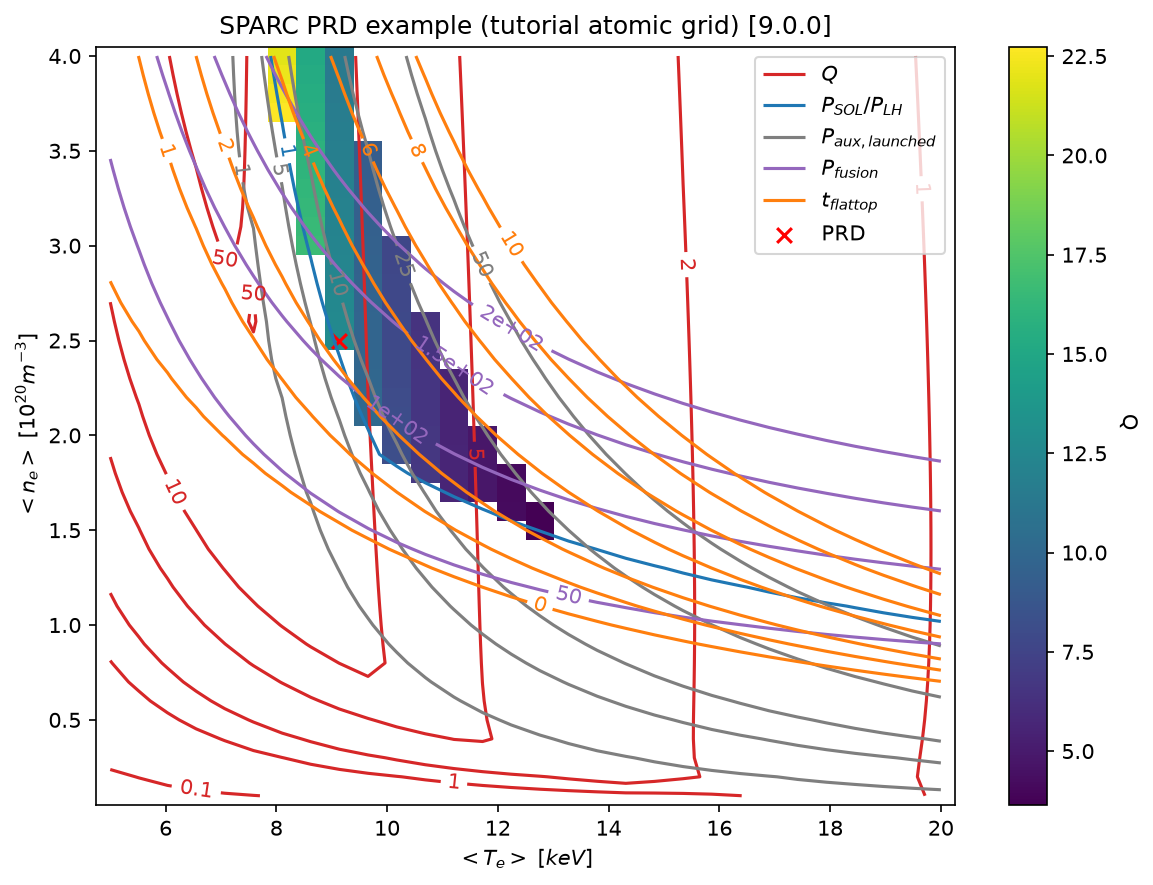

In [12]:
upstream_style = cfs.read_plot_style(upstream_plots["POPCON for SPARC PRD"])
fig, ax = make_plot(upstream_result, upstream_style, upstream_points,
                    title="SPARC PRD example (tutorial atomic grid)")
fig.savefig(run_dir / "01_upstream_SPARC_PRD.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

**How to read that picture:** choose an x-axis temperature and y-axis density.
A contour labelled 10 on the Q family means a gain of 10 at points on that
line. A 25 MW auxiliary contour means that much heating is required along
its line. Intersections give several quantities at one candidate state.
The coloured fill and PRD marker use the example's selection rules. Blank
fill alone does not mean the solver failed: a plotted region may simply
fail one of the requested plotting conditions.

### Save the example and its input copy (file handling)

The next cell only saves files. `safe_dump` writes a Python dictionary back
to YAML; `shutil.copy2` copies a file. The saved case has its own plot files
and an adjusted relative atomic-data path because it lives in a new folder.
`write_dataset_to_netcdf` serializes the full results, converting units and
option objects to forms the file can store. Use the package's
`read_dataset_from_netcdf` to restore those units/options later.

In [13]:
upstream_case_dir = cases_dir / "01_upstream_SPARC_PRD"
upstream_case_dir.mkdir()
with open(upstream_file) as file:
    upstream_snapshot = yaml.safe_load(file)
# Paths in this saved copy are relative to its new location under outputs/.
upstream_snapshot["radas_dir"] = "CASE_DIR/" + os.path.relpath(data_dir, upstream_case_dir)
upstream_snapshot["plots"] = {
    "POPCON for SPARC PRD": "CASE_DIR/plot_popcon.yaml",
    "Remapped SPARC PRD": "CASE_DIR/plot_remapped.yaml",
}
with open(upstream_case_dir / "input.yaml", "w") as file:
    yaml.safe_dump(upstream_snapshot, file, sort_keys=False)
for name in ["plot_popcon.yaml", "plot_remapped.yaml"]:
    shutil.copy2(upstream_file.parent / name, upstream_case_dir / name)
cfs.file_io.write_dataset_to_netcdf(upstream_result, upstream_case_dir / "results.nc")

## 5. Work through the FIRE input

We now use a shorter core-plasma recipe and FIRE's 2002 H-mode machine values.
We do not transfer SPARC's divertor and solenoid engineering assumptions to
FIRE. The FIRE input is printed in full below so the lesson is self-contained.

| FIRE input group | Meaning |
|---|---|
| `major_radius`, `inverse_aspect_ratio` | Distance R from the tokamak centre to the plasma axis, and a/R. Here R = 2.14 m and a = 0.595 m. |
| `magnetic_field_on_axis`, `plasma_current` | B = 10 T and Ip = 7.7e6 A. |
| `areal_elongation` | Cross-sectional area divided by pi a^2; a shape measure, here 1.85. |
| `elongation_ratio_sep_to_areal` | Converts that value to elongation at the confined-plasma boundary, here 2.0. |
| `triangularity_psi95`, `triangularity_ratio_sep_to_psi95` | D-shaping near the edge and conversion to boundary triangularity. |
| `fusion_reaction`, `heavier_fuel_species_fraction` | `DTFusionBoschHale` selects the package's D-T reactivity fit; 0.5 is an equal D/T fuel mixture. |
| `ion_to_electron_temp_ratio` | Ti/Te. Our choice of 1 assumes equal ion and electron temperatures. |
| Density/temperature `peaking` values | Central value divided by volume average. A peaked profile can change fusion even at fixed average density/temperature. |
| `energy_confinement_scaling`, `confinement_time_scalar` | Choose ITER98y2 and multiply its confinement time by H98 = 1.03. H98 is not a percentage of heating power. |
| `confinement_threshold_scalar` | Multiplies the L-H transition-power threshold. This is separate from H98. |
| `fraction_of_external_power_coupled` | Absorbed/launched auxiliary power. We choose 1 here. |
| `intrinsic_impurity_concentration` | Assumed impurity-ion densities divided by electron density. These are number ratios, not mass fractions. |
| `radiated_power_method`, `radiated_power_scalar` | Use RADAS atomic data for radiation, with multiplier 1. |
| `radas_dir` | Where `read_atomic_data` finds the tables. |
| `grid` | 31 average densities times 33 average temperatures: 1,023 candidate states. |

FIRE values are drawn from [Meade et al. (2002), Table I](https://fire.pppl.gov/fec2002_FT2_6_reprint4.pdf).
Equal Ti/Te, identical ion/electron density peaking, and the species mix are
modelling assumptions. The paper's Zeff = 1.5 does not uniquely specify an
impurity mixture. Here **Zeff** is a charge-weighted measure of composition,
calculated from our mixture; **dilution** is the fuel-ion density divided by
electron density. Impurities supply electrons without supplying D-T fuel.

In [14]:
fire_file = tutorial_dir / "inputs/fire_h_mode.yaml"
print("FIRE input:", fire_file)
print(fire_file.read_text())

FIRE input: /home/youeric/openmc-projects/ZachClass/POPCON/CFSPOPCON/inputs/fire_h_mode.yaml
# FIRE H-mode: Meade et al. (2002), Table I.
# Retain the core workflow; SPARC divertor/solenoid inputs do not describe FIRE.
algorithms:
  - read_atomic_data
  - set_up_impurity_concentration_array
  - calc_minor_radius_from_inverse_aspect_ratio
  - calc_separatrix_elongation_from_areal_elongation
  - calc_separatrix_triangularity_from_triangularity95
  - calc_vertical_minor_radius_from_elongation_and_minor_radius
  - calc_plasma_volume
  - calc_plasma_surface_area
  - calc_f_shaping_for_qstar
  - calc_q_star_from_plasma_current
  - calc_average_ion_mass
  - calc_average_ion_temp_from_temperature_ratio
  - calc_zeff_and_dilution_due_to_impurities
  - calc_plasma_stored_energy
  - read_confinement_scalings
  - solve_energy_confinement_scaling_for_input_power
  - calc_beta_toroidal
  - calc_beta_poloidal
  - calc_beta_total
  - calc_beta_normalized
  - calc_peak_electron_temp
  - calc_peak_ion_t

### Follow the calculation names in `algorithms`

The sequence is important: geometry gives a volume, stored energy and the
confinement law give total required power, profiles give spatially
integrated reaction/radiation rates, and heating terms give auxiliary power.
The long names are existing package calculations, not functions defined by
this tutorial. The table at the end explains every FIRE recipe entry.

We can ask a registered calculation which named inputs it needs and what it
returns. This is useful before editing a recipe: changing the list is not
enough if the new step needs inputs that have not been provided.

In [15]:
for name in ["calc_plasma_stored_energy", "solve_energy_confinement_scaling_for_input_power", "calc_fusion_power", "calc_auxiliary_power"]:
    step = cfs.registry[name]
    print(name)
    print("  required inputs:", step.required_input_keys)
    print("  returns:", step.return_keys)

calc_plasma_stored_energy
  required inputs: ['average_electron_density', 'average_electron_temp', 'average_ion_density', 'summed_impurity_density', 'average_ion_temp', 'plasma_volume']
  returns: ['plasma_stored_energy']
solve_energy_confinement_scaling_for_input_power
  required inputs: ['confinement_time_scalar', 'plasma_current', 'magnetic_field_on_axis', 'average_electron_density', 'major_radius', 'areal_elongation', 'separatrix_elongation', 'inverse_aspect_ratio', 'average_ion_mass', 'triangularity_psi95', 'separatrix_triangularity', 'plasma_stored_energy', 'q_star', 'energy_confinement_scaling']
  returns: ['energy_confinement_time', 'P_in']
calc_fusion_power
  required inputs: ['fusion_reaction', 'ion_temp_profile', 'heavier_fuel_species_fraction', 'fuel_ion_density_profile', 'rho', 'plasma_volume']
  returns: ['P_fusion', 'P_neutron', 'P_alpha']
calc_auxiliary_power
  required inputs: ['P_in', 'P_alpha', 'P_ohmic', 'fraction_of_external_power_coupled']
  returns: ['P_external'

Read, validate, and package the FIRE inputs exactly as for SPARC. The
returned `fire_points` and `fire_plots` dictionaries are empty; we select a
point directly and load the FIRE plot style separately. The case-copy
section saves the same inputs with a path appropriate to the output folder.

In [16]:
fire_inputs, fire_algorithm, fire_points, fire_plots = cfs.read_case(tutorial_dir / "inputs/fire_h_mode.yaml")
fire_inputs["radas_dir"] = data_dir
fire_algorithm.validate_inputs(fire_inputs, raise_error_on_missing_inputs=True)
fire_input_dataset = xr.Dataset(fire_inputs)

print(fire_input_dataset[["major_radius", "plasma_current", "average_electron_density", "average_electron_temp"]])

<xarray.Dataset> Size: 1kB
Dimensions:                       (dim_average_electron_density: 31,
                                   dim_average_electron_temp: 33)
Coordinates:
  * dim_average_electron_density  (dim_average_electron_density) float64 248B ...
  * dim_average_electron_temp     (dim_average_electron_temp) float64 264B 2....
Data variables:
    major_radius                  float64 8B [m] 2.14
    plasma_current                float64 8B [A] 7.7e+06
    average_electron_density      (dim_average_electron_density) float64 248B [1e19 m^-3] ...
    average_electron_temp         (dim_average_electron_temp) float64 264B [keV] ...


Now calculate the FIRE grid. This uses the same method as the small
Greenwald example and SPARC, but executes the whole FIRE recipe.

In [17]:
fire_result = fire_algorithm.update_dataset(fire_input_dataset)

## 6. Select and inspect one state

`.sel(..., method="nearest")` selects by coordinate **value**. A density of
45 means 45 x 10^19 m^-3, not array entry 45. If that value is between grid
samples, `nearest` picks the closest sample. `.isel(...)`, used later for
the radial axis, instead selects by integer **position**, starting at zero.
Selecting both scan coordinates leaves a single operating state; its
radial profiles still have a radial dimension.

CFSPOPCON quantities are DataArrays with Pint units. The helper `plain`
has two arguments: a Dataset and a variable name. It converts that variable
to CFSPOPCON's documented default unit, then `.pint.dequantify()` moves the
unit to an attribute and leaves numerical data for plotting/export. It
returns a DataArray, preserving dimension names. It does not change the
original Dataset or run physics. `float(...)` is used only after selecting
a single number. This is the only helper function we define in this lesson.

In [18]:
def plain(dataset, variable):
    """Return a variable as a DataArray in its default units, for display."""
    return cfs.convert_to_default_units(dataset[variable], variable).pint.dequantify()


point = fire_result.sel(dim_average_electron_density=sample_density_1e19_m3,
                        dim_average_electron_temp=sample_average_Te_keV, method="nearest")
print(point[["average_electron_density", "average_electron_temp", "z_effective", "dilution"]])

<xarray.Dataset> Size: 48B
Dimensions:                       ()
Coordinates:
    dim_average_electron_density  float64 8B 45.0
    dim_average_electron_temp     float64 8B 8.0
Data variables:
    average_electron_density      float64 8B [1e19 m^-3] 45.0
    average_electron_temp         float64 8B [keV] 8.0
    z_effective                   float64 8B [] 1.502
    dilution                      float64 8B [] 0.9232


### Check the shape and radial profiles

`rho` is the package's normalized radial coordinate: near zero at the core
and near one at the confined boundary. A profile describes how density or
temperature changes across that radius. The lines are divided by their
central values (`isel(dim_rho=0)`) so their shapes can be compared on one
axis. This normalization is for display, not a change to the calculation.

`plt.subplots(1, 2)` creates two Axes in one Figure: `axes[0]` for the shape,
`axes[1]` for profiles. The trigonometric boundary curve is an illustrative
D-shaped cross section using the stated size/shape parameters. It does not
solve an equilibrium. `set_aspect("equal")` makes one metre equally long
vertically and horizontally. The plotted profiles, in contrast, are taken
directly from the calculated Dataset at the selected point.

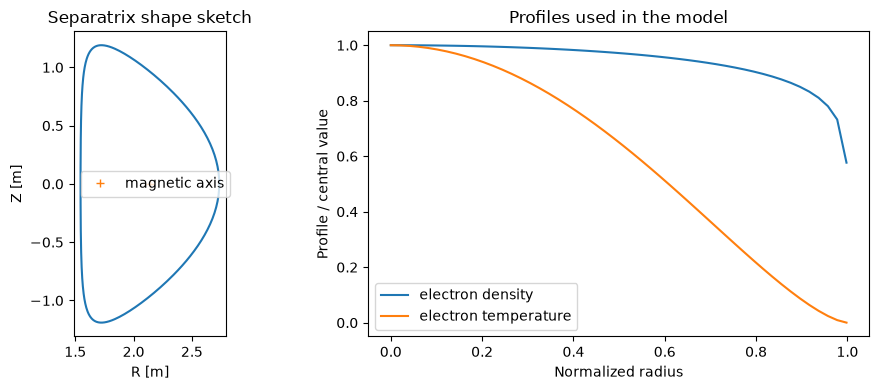

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
theta = np.linspace(0, 2 * np.pi, 300)
R_m = float(plain(fire_result, "major_radius"))
a_m = float(plain(fire_result, "minor_radius"))
kappa = float(plain(fire_result, "separatrix_elongation"))
delta = float(plain(fire_result, "separatrix_triangularity"))
axes[0].plot(R_m + a_m * np.cos(theta + np.arcsin(delta) * np.sin(theta)), kappa * a_m * np.sin(theta))
axes[0].plot(R_m, 0, "+", label="magnetic axis")
axes[0].set(xlabel="R [m]", ylabel="Z [m]", title="Separatrix shape sketch")
axes[0].set_aspect("equal")
axes[0].legend()
for variable, label in [("electron_density_profile", "electron density"), ("electron_temp_profile", "electron temperature")]:
    profile = plain(point, variable)
    axes[1].plot(plain(point, "rho"), profile / profile.isel(dim_rho=0), label=label)
axes[1].set(xlabel="Normalized radius", ylabel="Profile / central value", title="Profiles used in the model")
axes[1].legend()
fig.tight_layout()
fig.savefig(run_dir / "02_FIRE_setup.png", dpi=150)
plt.show()
plt.close(fig)

## 7. Identify points that can satisfy this power balance

The package clips negative auxiliary heating to zero. A negative *signed*
requirement means calculated self-heating already exceeds the loss for
the requested state: supplying zero power does not make that temperature
an exact steady state. A very large Q there should not be treated as a
demonstrated operating point.

A **mask** is an array of True/False values, one per grid point. Here it
requires a finite, positive signed heating requirement, radiation no larger
than total input power, and bootstrap-current fraction between zero and one.
Bootstrap current is pressure-driven current; its fraction describes how
much of the total current that model attributes to this effect.
`&` combines the conditions point by point. Parentheses keep each comparison
separate. This initial mask is not yet our heating/beta/Greenwald limits.

In [20]:
required_aux_MW = plain(fire_result, "P_in") - plain(fire_result, "P_alpha") - plain(fire_result, "P_ohmic")
physical = (
    np.isfinite(required_aux_MW) & (required_aux_MW > 0)
    & (plain(fire_result, "P_radiation") <= plain(fire_result, "P_in"))
    & (plain(fire_result, "bootstrap_fraction") >= 0)
    & (plain(fire_result, "bootstrap_fraction") <= 1)
)

### Load and use the FIRE plot file

In `plot_fire.yaml`, `coords.x` chooses average Te in keV; `coords.y`
chooses average density displayed in `n20`. That conversion affects only
the displayed axis. Each `contour` key names a calculated output;
`levels: [5, 15, 30, 60, 100]` for auxiliary power means those MW values.
Changing these levels changes the drawing, not the calculation.

We copy the results for plotting and use `.where(physical)` on the plotted
quantities. This retains True points and replaces False points with missing
values, leaving the original full results available. Passing `{}` as the
third `make_plot` argument means there are no automatic point-selection rules.

type: popcon
figsize: [9, 6]
show_dpi: 120
legend_loc: upper left
coords:
  x:
    dimension: average_electron_temp
    label: '$\langle T_e\rangle$ [keV]'
    units: keV
  y:
    dimension: average_electron_density
    label: '$\langle n_e\rangle$ [$10^{20}$ m$^{-3}$]'
    units: n20
contour:
  P_auxiliary_absorbed:
    label: '$P_{aux,absorbed}$ [MW]'
    units: MW
    levels: [5, 15, 30, 60, 100]
    color: tab:red
    format: '.0f'
  Q:
    label: '$Q$'
    levels: [1, 5, 10, 20]
    color: tab:blue
    format: '.0f'
  P_fusion:
    label: '$P_{fusion}$ [MW]'
    units: MW
    levels: [50, 150, 300]
    color: tab:gray
    format: '.0f'



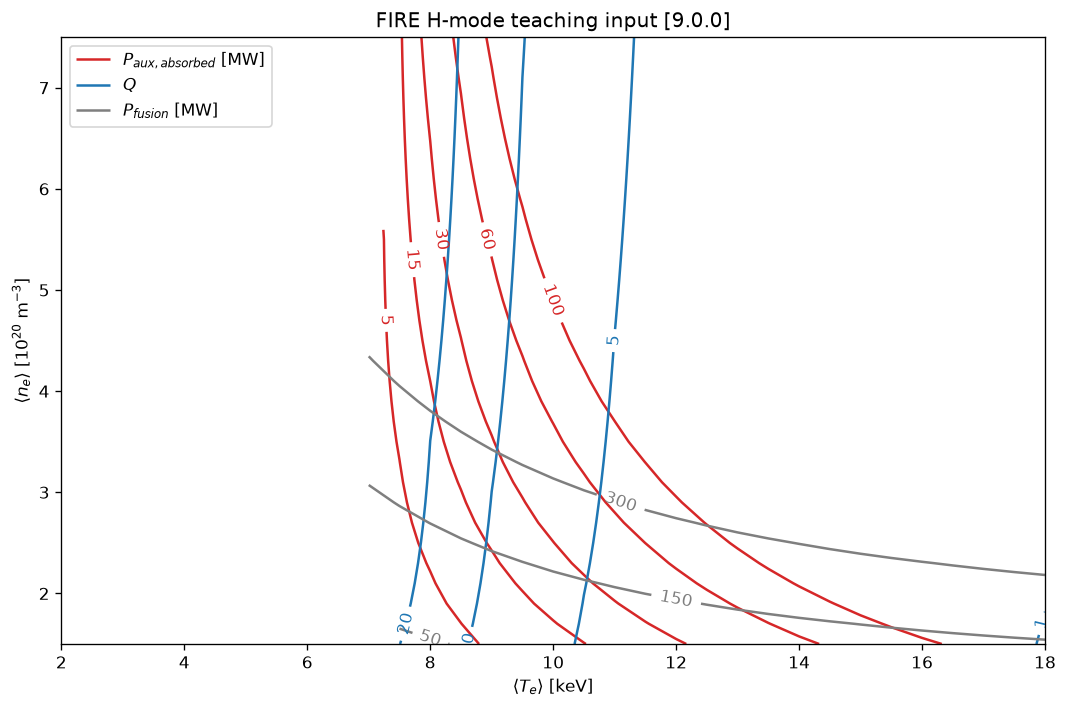

In [21]:
fire_style = cfs.read_plot_style(tutorial_dir / "inputs/plot_fire.yaml")
print((tutorial_dir / "inputs/plot_fire.yaml").read_text())
fire_for_plot = fire_result.copy()
for variable in fire_style["contour"]:
    fire_for_plot[variable] = fire_result[variable].where(physical)
fig, ax = make_plot(fire_for_plot, fire_style, {}, title="FIRE H-mode teaching input")
fig.savefig(run_dir / "03_FIRE_POPCON.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

Read the plot at one density and temperature, following the appropriate
colour's labels. Grey fusion-power contours, red auxiliary-power contours,
and blue Q contours describe different quantities at the same state.
The missing portions here are masked by our power-balance conditions.
The picture still has no hardware or H-mode-access restrictions applied.

### Print the power terms at the selected point

`plain(point, variable)` now contains a scalar, so `float` gives its number
in MW. Each dictionary appended to `power_rows` becomes one table row;
`pd.DataFrame` turns the rows into a table. `to_csv(index=False)` writes the
table without a redundant row-number column. In a positive-heating state,
verify `P_in = P_alpha + P_ohmic + P_auxiliary_absorbed` and
`P_SOL = P_in - P_radiation`. `P_fusion` is listed for context, not added to
the heating balance a second time.

In [22]:
power_rows = []
for variable in ["P_in", "P_alpha", "P_ohmic", "P_auxiliary_absorbed", "P_radiation", "power_crossing_separatrix", "P_fusion"]:
    power_rows.append({"quantity": variable, "power_MW": float(plain(point, variable))})
power_table = pd.DataFrame(power_rows)
power_table.to_csv(run_dir / "inspection_point_power.csv", index=False)
print(power_table.to_string(index=False))

                 quantity   power_MW
                     P_in 102.288889
                  P_alpha  83.824875
                  P_ohmic   1.057428
     P_auxiliary_absorbed  17.406586
              P_radiation  35.671335
power_crossing_separatrix  66.617554
                 P_fusion 419.124373


### Save the FIRE case (file handling)

As for SPARC, retain a readable input snapshot and the full numerical
Dataset. The snapshot below is also the starting dictionary for the
confinement exercise; its atomic-data path is relative to a saved case.

In [23]:
fire_case_dir = cases_dir / "02_FIRE_H_mode"
fire_case_dir.mkdir()
with open(tutorial_dir / "inputs/fire_h_mode.yaml") as file:
    fire_parameters = yaml.safe_load(file)
fire_snapshot = fire_parameters.copy()
fire_snapshot["radas_dir"] = "CASE_DIR/" + os.path.relpath(data_dir, fire_case_dir)
with open(fire_case_dir / "input.yaml", "w") as file:
    yaml.safe_dump(fire_snapshot, file, sort_keys=False)
print(fire_input_dataset[["major_radius", "plasma_current", "average_electron_density", "average_electron_temp"]])
cfs.file_io.write_dataset_to_netcdf(fire_result, fire_case_dir / "results.nc")

<xarray.Dataset> Size: 1kB
Dimensions:                       (dim_average_electron_density: 31,
                                   dim_average_electron_temp: 33)
Coordinates:
  * dim_average_electron_density  (dim_average_electron_density) float64 248B ...
  * dim_average_electron_temp     (dim_average_electron_temp) float64 264B 2....
Data variables:
    major_radius                  float64 8B [m] 2.14
    plasma_current                float64 8B [A] 7.7e+06
    average_electron_density      (dim_average_electron_density) float64 248B [1e19 m^-3] ...
    average_electron_temp         (dim_average_electron_temp) float64 264B [keV] ...


## 8. Extension: vary confinement while holding the other inputs fixed

H98 is the multiplier in `tau_E = H98 * tau_ITER98y2`. The three choices
below are alternate assumptions for the same machine. The density and
temperature grids, composition, and profiles remain fixed.

Follow one pass through the loop:

1. `enumerate` supplies a panel number (`column`) and a value (`H98`).
2. `copy(deep=True)` makes independent input data; changing this case does
   not change the baseline inputs. Assign a **dimensionless quantity** to
   `confinement_time_scalar`, since it remains a unit-aware input.
3. `update_dataset` recalculates the full recipe from those inputs.
4. Save the case and apply the same physical mask used above.
5. Give an existing panel to `make_plot(..., ax=...)` instead of creating a
   separate figure. All panels use the same contour levels.
6. Select the same density/temperature as before and add one summary row.

The row includes the signed heating requirement and a physical-point flag.
If that flag is False, the package's clipped zero heating and large Q are
not a balanced auxiliary-heated state. Compare the required heating at the
same state before comparing contours at different states.

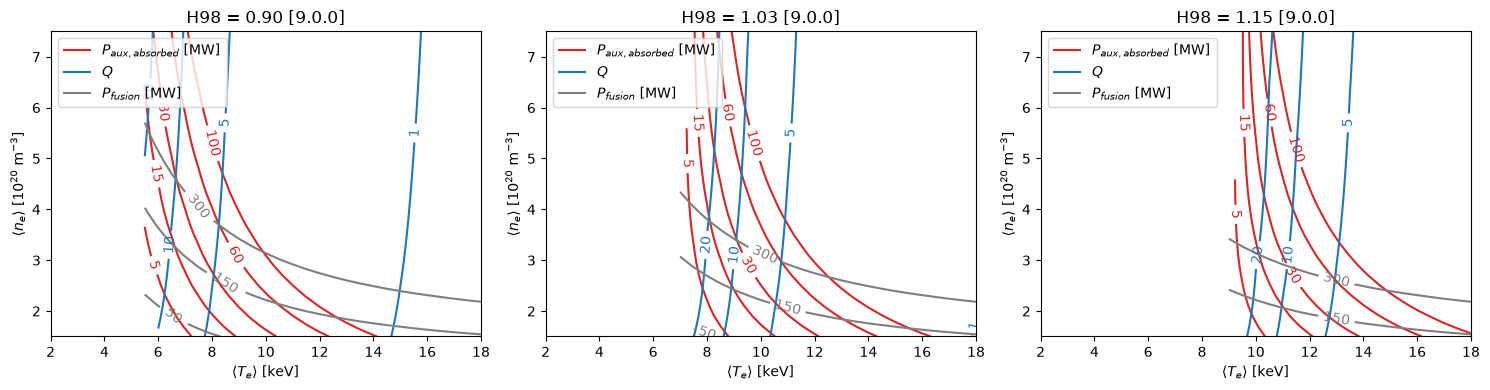

       case  H98  R_m   a_m  B_T  Ip_MA  density_1e19_m3  Te_keV   Paux_MW  signed_Paux_requirement_MW  Pfusion_MW          Q  positive_heating_physical_point
03_H98_0.90 0.90 2.14 0.595 10.0    7.7             45.0     8.0 73.185593                   73.185593  419.124373   5.645303                             True
03_H98_1.03 1.03 2.14 0.595 10.0    7.7             45.0     8.0 17.406586                   17.406586  419.124373  22.699526                             True
03_H98_1.15 1.15 2.14 0.595 10.0    7.7             45.0     8.0  0.000000                  -13.195472  419.124373 396.361988                            False


In [24]:
scan_rows = []
fig, axes = plt.subplots(1, len(confinement_factors), figsize=(15, 4), squeeze=False)
for column, H98 in enumerate(confinement_factors):
    case_name = f"03_H98_{H98:.2f}"
    case_dir = cases_dir / case_name
    case_dir.mkdir()
    changed_inputs = fire_input_dataset.copy(deep=True)
    changed_inputs["confinement_time_scalar"] = H98 * ureg.dimensionless
    result = fire_algorithm.update_dataset(changed_inputs)
    cfs.file_io.write_dataset_to_netcdf(result, case_dir / "results.nc")
    snapshot = fire_snapshot.copy()
    snapshot["confinement_time_scalar"] = H98
    with open(case_dir / "input.yaml", "w") as file:
        yaml.safe_dump(snapshot, file, sort_keys=False)
    signed_aux = plain(result, "P_in") - plain(result, "P_alpha") - plain(result, "P_ohmic")
    scan_physical = (
        np.isfinite(signed_aux) & (signed_aux > 0)
        & (plain(result, "P_radiation") <= plain(result, "P_in"))
        & (plain(result, "bootstrap_fraction") >= 0)
        & (plain(result, "bootstrap_fraction") <= 1)
    )
    result_for_plot = result.copy()
    for variable in fire_style["contour"]:
        result_for_plot[variable] = result[variable].where(scan_physical)
    make_plot(result_for_plot, fire_style, {}, title=f"H98 = {H98:.2f}", ax=axes[0, column])
    scan_point = result.sel(dim_average_electron_density=sample_density_1e19_m3,
                            dim_average_electron_temp=sample_average_Te_keV, method="nearest")
    scan_rows.append({
        "case": case_name, "H98": H98, "R_m": R_m, "a_m": a_m,
        "B_T": float(plain(result, "magnetic_field_on_axis")),
        "Ip_MA": float(plain(result, "plasma_current")) / 1e6,
        "density_1e19_m3": float(plain(scan_point, "average_electron_density")),
        "Te_keV": float(plain(scan_point, "average_electron_temp")),
        "Paux_MW": float(plain(scan_point, "P_auxiliary_absorbed")),
        "signed_Paux_requirement_MW": float(signed_aux.sel(
            dim_average_electron_density=sample_density_1e19_m3,
            dim_average_electron_temp=sample_average_Te_keV, method="nearest")),
        "Pfusion_MW": float(plain(scan_point, "P_fusion")), "Q": float(plain(scan_point, "Q")),
        "positive_heating_physical_point": bool(scan_physical.sel(
            dim_average_electron_density=sample_density_1e19_m3,
            dim_average_electron_temp=sample_average_Te_keV, method="nearest")),
    })
fig.tight_layout()
fig.savefig(run_dir / "04_confinement_scan.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
scan_table = pd.DataFrame(scan_rows)
scan_table.to_csv(run_dir / "confinement_scan.csv", index=False)
print(scan_table.to_string(index=False))

## 9. Extension: add selected operating limits

The `physical` mask asked whether the calculation represented an
auxiliary-heated balance. The `allowed` mask adds choices about which
candidate states we will retain:

| Condition | Meaning |
|---|---|
| Auxiliary power <= 30 MW | Our illustrative heating-capacity cap. |
| beta_N <= 3 | Our illustrative normalized pressure limit. Beta compares plasma pressure with magnetic pressure; beta_N also accounts for size, field, and current. This criterion is not an MHD stability calculation. |
| Greenwald fraction <= 1 | Density divided by the empirical Greenwald density. This package uses volume-average density as a proxy for the commonly used line average. |
| P_SOL / P_LH >= 1 | An H-mode-access check: boundary loss power must reach the empirical L-H threshold. Here the package uses its Martin scaling with a low-density correction. |

The H98 confinement model is still evaluated over the whole grid; this
mask does not switch sub-threshold points to a different confinement model.
`plain(..., "normalized_beta")` returns values in the package's default
units, m percent T / MA. Its numerical beta_N already uses beta in percent;
do not multiply it by 100 again when applying the limit.
These are selected scoping limits, not all engineering and plasma limits.
At the paper's density 4.5e20 m^-3, this density convention gives a Greenwald
fraction of about 0.65; it need not equal the separately quoted 0.7.

For the shading, Matplotlib needs rows ordered as density and columns as
temperature. `.transpose(density_dimension, temperature_dimension)` makes
that order explicit; it does not swap the physical coordinate values.
`.astype(int)` converts False/True to 0/1, and `contourf` shades values near
one. `.broadcast_like(...)` repeats a quantity along any missing grid axis
so the threshold contour has the full two-dimensional shape.
Dividing the displayed density by 10 converts n19 numbers to n20 numbers.

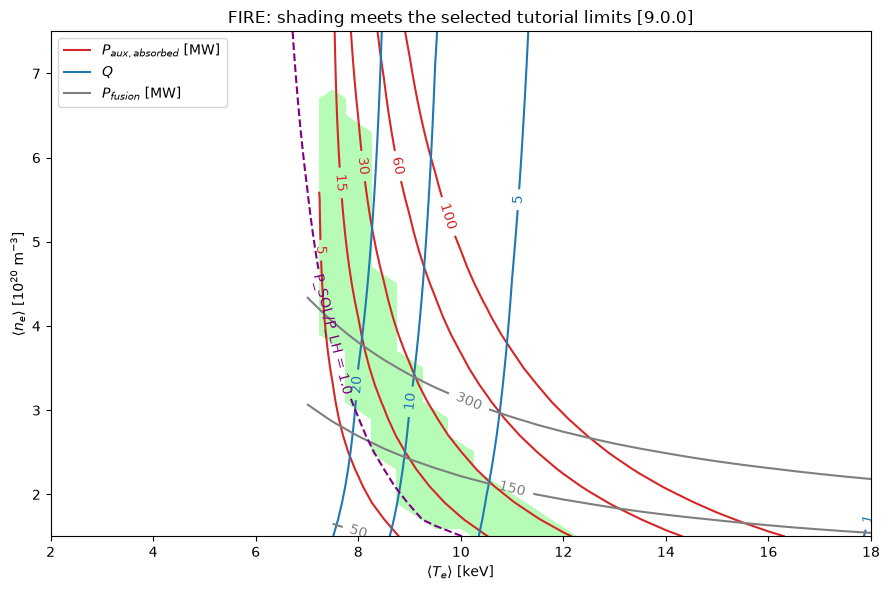

Points meeting these selected limits: 74


In [25]:
allowed = (
    physical
    & (plain(fire_result, "P_auxiliary_absorbed") <= auxiliary_power_limit_MW)
    & (plain(fire_result, "normalized_beta") <= normalized_beta_limit)
    & (plain(fire_result, "greenwald_fraction") <= greenwald_fraction_limit)
    & (plain(fire_result, "ratio_of_P_SOL_to_P_LH") >= minimum_P_SOL_over_P_LH)
)
density_dimension = "dim_average_electron_density"
temperature_dimension = "dim_average_electron_temp"
x = plain(fire_result, "average_electron_temp")
y = plain(fire_result, "average_electron_density") / 10.0
fig, ax = plt.subplots(figsize=(9, 6))
ax.contourf(x, y, allowed.transpose(density_dimension, temperature_dimension).astype(int),
            levels=[0.5, 1.5], colors=["palegreen"], alpha=0.7)
make_plot(fire_for_plot, fire_style, {}, title="FIRE: shading meets the selected tutorial limits", ax=ax)
LH_ratio = plain(fire_result, "ratio_of_P_SOL_to_P_LH").broadcast_like(required_aux_MW)
LH_contour = ax.contour(x, y, LH_ratio.transpose(density_dimension, temperature_dimension),
                        levels=[minimum_P_SOL_over_P_LH], colors="purple", linestyles="--")
ax.clabel(LH_contour, fmt="P_SOL/P_LH = %.1f")
fig.savefig(run_dir / "05_selected_operating_limits.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Points meeting these selected limits:", int(allowed.sum()))

## 10. Export and find your work

The next cell builds a smaller numerical Dataset for a CSV. It includes
selected variables and the two masks. `to_dataframe()` expands their named
coordinates into table rows; `reset_index()` makes those coordinates normal
columns. Renaming columns records units because a plain CSV cannot preserve
Pint objects. The full NetCDF files retain far more information.

A `metadata` dictionary stores the settings and counts used in this run.
`json.dump(..., indent=2)` saves it as readable text. Copies of the plot and
atomic-generation configurations explain how the figures/tables were made.
These operations save results; they do not perform additional plasma physics.

```text
outputs/<run>/
    01_upstream_SPARC_PRD.png     example figure
    02_FIRE_setup.png            shape and profiles
    03_FIRE_POPCON.png           FIRE contours
    04_confinement_scan.png      H98 exercise
    05_selected_operating_limits.png
    FIRE_grid.csv               one row per FIRE grid point
    inspection_point_power.csv  one selected state's power terms
    confinement_scan.csv        same state at each H98
    run_summary.json            settings, versions, point counts
    cases/<case_name>/input.yaml, results.nc
```

To reload a full saved case, use the following with your own run folder:

```python
results = cfs.file_io.read_dataset_from_netcdf(
    Path("outputs/<run>/cases/02_FIRE_H_mode/results.nc")
)
```

In [26]:
csv_dataset = xr.Dataset()
for variable in ["average_electron_density", "average_electron_temp", "P_in", "P_alpha", "P_ohmic",
                 "P_auxiliary_absorbed", "P_fusion", "P_radiation", "Q", "normalized_beta",
                 "greenwald_fraction", "ratio_of_P_SOL_to_P_LH", "energy_confinement_time"]:
    csv_dataset[variable] = plain(fire_result, variable)
csv_dataset["positive_heating_physical_region"] = physical
csv_dataset["meets_selected_limits"] = allowed
table = csv_dataset.to_dataframe().reset_index()
table = table.rename(columns={"average_electron_density": "density_1e19_m3", "average_electron_temp": "Te_keV",
                              "energy_confinement_time": "tau_E_s", "normalized_beta": "beta_N_percent_m_T_per_MA"})
for variable in ["P_in", "P_alpha", "P_ohmic", "P_auxiliary_absorbed", "P_fusion", "P_radiation"]:
    table = table.rename(columns={variable: variable + "_MW"})
table["R_m"] = R_m
table["a_m"] = a_m
table["B_T"] = float(plain(fire_result, "magnetic_field_on_axis"))
table["Ip_MA"] = float(plain(fire_result, "plasma_current")) / 1e6
table["H98"] = fire_parameters["confinement_time_scalar"]
table.to_csv(run_dir / "FIRE_grid.csv", index=False)
shutil.copy2(tutorial_dir / "inputs/plot_fire.yaml", run_dir / "plot_fire.yaml")
shutil.copy2(atomic_config_file, run_dir / "radas_config.yaml")
metadata = {
    "cfspopcon_version": version("cfspopcon"), "radas_version": version("radas"),
    "reference": "Meade et al. 2002, Table I, FIRE H-mode",
    "fire_parameters": fire_parameters, "confinement_factors": confinement_factors,
    "atomic_data_directory": str(data_dir),
    "atomic_configuration": yaml.safe_load(atomic_config_file.read_text()),
    "tutorial_limits": {"Paux_MW": auxiliary_power_limit_MW, "beta_N": normalized_beta_limit,
                        "density_over_nG": greenwald_fraction_limit, "P_SOL_over_P_LH_min": minimum_P_SOL_over_P_LH},
    "grid_points": int(required_aux_MW.size), "positive_heating_physical_points": int(physical.sum()),
    "points_meeting_selected_limits": int(allowed.sum()),
}
with open(run_dir / "run_summary.json", "w") as file:
    json.dump(metadata, file, indent=2)
print("Saved this run in:", run_dir)

Saved this run in: /home/youeric/openmc-projects/ZachClass/POPCON/CFSPOPCON/outputs/20261015_192828_917990


## 11. Where to make your next edit

| What you want to change | Where to edit | What to rerun |
|---|---|---|
| FIRE size, field, current, composition, profile peaking | `inputs/fire_h_mode.yaml` ordinary values | The FIRE reading cell onward, or Run All. |
| Density/temperature range or number of POPCON points | The same file's `grid` block | Read the file again, then calculate again. |
| Which physics steps run | The same file's `algorithms` list, after checking their inputs/outputs | Read and validate again. Preserve prerequisite order. |
| Which contours are visible | `inputs/plot_fire.yaml` | Reload the style and redraw; no new plasma calculation is needed. |
| H98 scan values or illustrative limits | Parameters near the top of this notebook/source | Rerun those parameter cells and the affected exercise, or Run All. |
| Atomic-table resolution | RADAS configuration plus separate generation step | Generate tables, point `data_dir` and `atomic_config_file` to the matching files, then rerun. |

After editing `tutorial.py`, update this notebook with
`jupytext --to ipynb tutorial.py` and run its cells again. The updated source
is the version to keep; editing only a generated notebook can lose changes.

Common errors: **file not found** means inspect `tutorial_dir` and the named
file; **missing atomic species** means complete the one-time RADAS setup;
**missing input** means check the YAML spelling and recipe order; **unit
error** means supply compatible physical units; **empty shading** means no
grid points meet the selected criteria, not necessarily a software failure.

For more detail, use the [physics glossary](https://cfspopcon.readthedocs.io/en/latest/doc_sources/physics_glossary.html)
and the installed functions' docstrings (`help(calc_greenwald_density_limit)`
is one example). The pinned [input reader](https://github.com/cfs-energy/cfspopcon/blob/527ce6bd490a003a56e336dfa9a0949cd8d7ed1a/cfspopcon/input_file_handling.py)
and [unit definitions](https://github.com/cfs-energy/cfspopcon/blob/527ce6bd490a003a56e336dfa9a0949cd8d7ed1a/cfspopcon/variables.yaml)
are the implementation references when examples on another version differ.

## Reference: every calculation in the FIRE recipe

This is a guide to the `algorithms` names printed earlier. Each row names
installed code. You can inspect its exact required inputs and return names
with `cfs.registry["the_name"].required_input_keys` and `.return_keys`, as we
did for four steps above. A later step can consume an earlier row's output.

| Calculation name | What it supplies to the next steps |
|---|---|
| `read_atomic_data` | Opens the generated species tables, supplying atomic-data interpolation objects. |
| `set_up_impurity_concentration_array` | Collects the named impurity concentrations into a species-labelled array. |
| `calc_minor_radius_from_inverse_aspect_ratio` | a = R times (a/R). |
| `calc_separatrix_elongation_from_areal_elongation` | Boundary elongation from areal elongation and the given ratio. |
| `calc_separatrix_triangularity_from_triangularity95` | Boundary triangularity from the near-edge value and ratio. |
| `calc_vertical_minor_radius_from_elongation_and_minor_radius` | Vertical size of the cross section. |
| `calc_plasma_volume` | Analytic confined-plasma volume for energy and power integrals. |
| `calc_plasma_surface_area` | Analytic surface area used in radiation/threshold-related estimates. |
| `calc_f_shaping_for_qstar` | Shape correction for the analytic edge safety-factor estimate. |
| `calc_q_star_from_plasma_current` | Approximate edge safety factor q_star from current, field, and shape; not a solved q profile. |
| `calc_average_ion_mass` | Average fuel-ion mass for the selected D/T mixture. |
| `calc_average_ion_temp_from_temperature_ratio` | Average Ti from average Te and Ti/Te. |
| `calc_zeff_and_dilution_due_to_impurities` | Effective charge and remaining fuel concentration using atomic charge states. |
| `calc_plasma_stored_energy` | Total thermal energy estimate from averages and volume. |
| `read_confinement_scalings` | Makes the built-in confinement scaling coefficients available. |
| `solve_energy_confinement_scaling_for_input_power` | Solves the chosen scaling and W/tau_E relation for P_in and confinement time. |
| `calc_beta_toroidal` | Pressure relative to toroidal magnetic pressure. |
| `calc_beta_poloidal` | Pressure relative to estimated poloidal magnetic pressure. |
| `calc_beta_total` | Combines toroidal and poloidal beta for total-field beta. |
| `calc_beta_normalized` | Normalizes that beta using size, field, and current. |
| `calc_peak_electron_temp` | Central Te from average Te and temperature peaking. |
| `calc_peak_ion_temp` | Central Ti from average Ti and temperature peaking. |
| `define_radial_grid` | Normalized radius samples for the one-dimensional profiles. |
| `calc_analytic_profiles` | Density and temperature profiles from averages, peaking, and dilution. |
| `calc_intrinsic_radiated_power_from_core` | Integrated core radiation including the configured impurity radiation, bremsstrahlung, and synchrotron terms. |
| `calc_bootstrap_fraction` | Estimate of the pressure-driven fraction of the current. |
| `calc_inductive_plasma_current` | Current left to be driven inductively after subtracting bootstrap current. |
| `calc_Spitzer_loop_resistivity` | Temperature-dependent starting resistivity estimate. |
| `calc_resistivity_trapped_enhancement` | Correction factor associated with trapped particles. |
| `calc_neoclassical_loop_resistivity` | Resistivity including effective-charge and trapped-particle corrections. |
| `calc_loop_voltage` | Inductive loop voltage from current, geometry, and resistivity. |
| `calc_ohmic_power` | Inductive current times loop voltage. |
| `calc_fusion_power` | Integrates reaction power over the profiles; returns total, neutron, and charged-product powers. |
| `calc_auxiliary_power` | External/absorbed/launched auxiliary powers from required input and self-heating; negative requirements are clipped. |
| `calc_fusion_gain` | Q from total fusion power and externally supplied heating. |
| `calc_power_crossing_separatrix` | P_SOL = P_in - radiation, clipped at zero. |
| `calc_LH_transition_threshold_power` | Empirical boundary-power threshold estimate for H-mode access. |
| `calc_ratio_P_LH` | P_SOL divided by the L-H threshold. |
| `calc_greenwald_density_limit` | Empirical density scale set by current and minor radius. |
| `calc_greenwald_fraction` | Average density divided by that scale. |

The longer upstream SPARC recipe also has core/edge impurity-seeding,
divertor heat-flow, inductance/flux, and pulse-duration calculations. Its
plot's flattop-duration condition uses that SPARC-specific flux budget.
Those extra engineering models are not necessary to understand the shorter
FIRE core workflow and have not been assumed to describe FIRE.